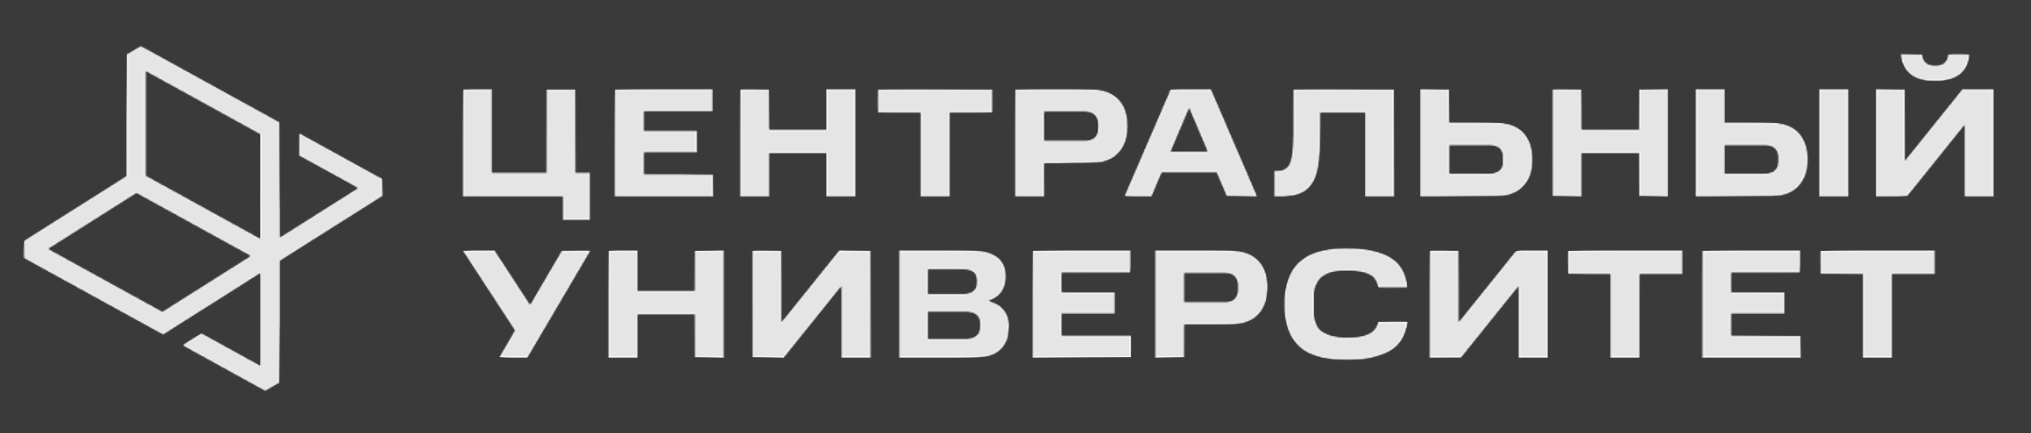

# Центр непрерывного образования

## Домашнее задание 5. Сегментация изображений (10 баллов + 1 бонусный балл)

# Формат сдачи

**<font color='plum'>По решению ноутбука используются следующие требования</font>**

- последовательно заполняйте все ячейки с комментарием `# YOUR CODE HERE`;
- не удаляйте ячейки с разметкой частей ноутбука и формулировками заданий;
- допускается создавать вспомогательные функции и ячейки для визуализации.

**<font color='plum'>По оформлению результатов используются следующие требования</font>**

- приводите изображения для проверки аугментаций и качества сегментации;
- после экспериментов формулируйте краткие выводы в markdown-ячейках;
- выводите только то, что необходимо для проверки решения.

**ФИО:**  
**Группа:**

## О задании

В работе используется `people_segmentation` — архив из материалов курса для бинарной сегментации людей на фотографиях. Это не датасет из `torchvision`: его нужно [скачать отдельно](https://disk.yandex.ru/d/tI6d3LBMHTwOnw) и распаковать рядом с ноутбуком.

В архиве каждая фотография имеет парную маску. Изображения хранятся в формате `.jpg`, маски — в формате `.png`; совпадающая часть имени файла задаёт соответствие, например `train/42.jpg` и `train_mask/42.png`. Маска задаёт два класса: человек и фон.

В используемой версии архива 1350 пар находятся в обучающей выборке и 141 пара — в тестовой. После распаковки в каталоге с ноутбуком должна быть структура:

```
people_segmentation/
    train/
    train_mask/
    test/
    test_mask/
```

В сыром задании источник исходных фотографий и разметки не указан. Поэтому в работе достаточно использовать архив как выданный учебный набор и не делать предположений о его происхождении.

<font color='OrangeRed'>**Важное замечание!**</font> Для обучения модели вам, вероятно, понадобится возможность работать на GPU. В Google Colab выберите в меню Runtime пункт Change runtime type, затем Hardware accelerator и T4 GPU. Перед длительным обучением убедитесь, что решение корректно работает на небольшом числе эпох.

--------

In [1]:
#!pip3 install torchvision
import os
import random

import numpy as np
import numpy.testing as npt
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.models import vgg13, VGG13_Weights
from torchvision.transforms import InterpolationMode
import torchvision.transforms.functional as TF
from PIL import Image

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Задания
--------

## <font color='DarkOrange'> **Задание 1 [1.5 балла]** </font>
---

Реализуйте `PhotosDataset`. Имена изображения и маски совпадают с точностью до расширения файла. Метод `__getitem__` должен вернуть пару `(image, mask)`, где `image` имеет режим `RGB`, а `mask` имеет режим `L`. Если `target_dir=None`, возвращайте только изображение.

Все преобразования в этом задании принимают и возвращают пару `(image, mask)`. Это необходимо, чтобы геометрические преобразования одинаково применялись к изображению и разметке.

In [2]:
class PhotosDataset(Dataset):
    def __init__(self, images_dir, target_dir=None, transforms=None):
        self.images_dir = images_dir
        self.target_dir = target_dir
        self.transforms = transforms

        self.images = sorted(os.listdir(images_dir))
        if target_dir is not None:
            self.targets = sorted(os.listdir(target_dir))
            
            # Извлекаем имена файлов без расширений прямо в сет
            img_names = {os.path.splitext(x)[0] for x in self.images}
            tgt_names = {os.path.splitext(x)[0] for x in self.targets}
            common = img_names & tgt_names

            # Фильтруем и собираем полные пути
            self.images = [os.path.join(images_dir, x)
                           for x in self.images if os.path.splitext(x)[0] in common]
            self.targets = [os.path.join(target_dir, x)
                            for x in self.targets if os.path.splitext(x)[0] in common]
        else:
            self.images = [os.path.join(images_dir, x) for x in self.images]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = Image.open(self.images[idx]).convert('RGB')

        if self.target_dir is not None:
            mask_l = Image.open(self.targets[idx]).convert('L')
            image, mask = self.transforms(image, mask_l)
            return image, mask
        else:
            return image

## <font color='DarkOrange'> **Задание 2 [1.5 балла]** </font>
---

Реализуйте классы `Compose`, `RandomHorizontalFlip`, `Resize`, `ToTensor` и `Normalize`.

- `RandomHorizontalFlip` с вероятностью `p` отражает и изображение, и маску по горизонтали.
- `Resize` приводит изображение и маску к размеру `size`. Для маски используйте интерполяцию ближайшим соседом.
- `ToTensor` переводит изображение в тензор и делает маску бинарной с помощью порога `0.5`.
- `Normalize` нормализует только изображение.

Используйте `torchvision.transforms.functional` для базовых операций.

In [3]:
class Compose:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, image, mask):
        for t in self.transforms:
            image, mask = t(image, mask)
        return image, mask
    

class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p
    def __call__(self, image, mask):
        if random.random() < self.p:
            image = TF.hflip(image)
            mask = TF.hflip(mask)
        return image, mask

class Resize:
    def __init__(self, size):
        self.size = size
    def __call__(self, image, mask):
        image = TF.resize(image, self.size)
        mask = TF.resize(mask, self.size, interpolation=InterpolationMode.NEAREST)
        return image, mask
        


class ToTensor:
    def __call__(self, image, mask):
        # Меняем порядок осей (размерностей). В NumPy изображения хранятся в формате 
        # HWC (Высота, Ширина, Каналы), а сверточные нейросети в PyTorch ожидают формат: 
        # CHW (Каналы, Высота, Ширина)
        # .float() / 255.0 приводит тип данных к вещественному (float) и нормализует 
        # пиксели из диапазона [0, 255] в диапазон [0.0, 1.0]

        image = torch.from_numpy(np.array(image)).permute(2, 0, 1).float() / 255.0
        
        # Переводим маску в тензор PyTorch
        mask = torch.from_numpy(np.array(mask)).unsqueeze(0).float()
        return image, (mask > 0.5).float()
       


class Normalize:
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std

    def __call__(self, image, mask):
        # Метод .view(3, 1, 1) изменяет размерность тензоров, чтобы значения 
        # корректно применились к трехмерному тензору изображения формата 
        # [Каналы, Высота, Ширина] ([C, H, W])

        mean = torch.tensor(self.mean, dtype=image.dtype).view(3, 1, 1)
        std = torch.tensor(self.std, dtype=image.dtype).view(3, 1, 1)
        image = (image - mean) / std
        return image, mask
        

In [4]:
_image = Image.fromarray(np.random.randint(0, 255, (80, 120, 3), dtype=np.uint8))
_mask = Image.fromarray(np.random.randint(0, 2, (80, 120), dtype=np.uint8) * 255)
_transforms = Compose([
    RandomHorizontalFlip(p=1.0),
    Resize((64, 96)),
    ToTensor(),
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
_image_t, _mask_t = _transforms(_image, _mask)
assert _image_t.shape == (3, 64, 96)
assert _mask_t.shape == (1, 64, 96)
assert set(_mask_t.unique().tolist()).issubset({0.0, 1.0})
print('Отлично!')

Отлично!


In [5]:
DATA_PATH = './people_segmentation'
IMAGE_SIZE = (320, 240)

train_transforms = Compose([
    RandomHorizontalFlip(p=0.5),
    Resize(IMAGE_SIZE),
    ToTensor(),
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
test_transforms = Compose([
    Resize(IMAGE_SIZE),
    ToTensor(),
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

DATA_READY = os.path.isdir(os.path.join(DATA_PATH, 'train'))
if DATA_READY:
    train_dataset = PhotosDataset(
        os.path.join(DATA_PATH, 'train'),
        os.path.join(DATA_PATH, 'train_mask'),
        transforms=train_transforms,
    )
    test_dataset = PhotosDataset(
        os.path.join(DATA_PATH, 'test'),
        os.path.join(DATA_PATH, 'test_mask'),
        transforms=test_transforms,
    )
    train_data_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
    test_data_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=0)
    print(f'Обучающая выборка: {len(train_dataset)}, тестовая выборка: {len(test_dataset)}')
else:
    print('Датасет не найден. Скачайте и распакуйте people_segmentation, затем перезапустите эту ячейку.')

Обучающая выборка: 1350, тестовая выборка: 141


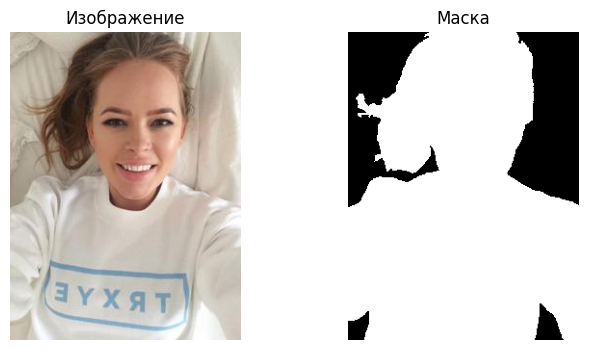

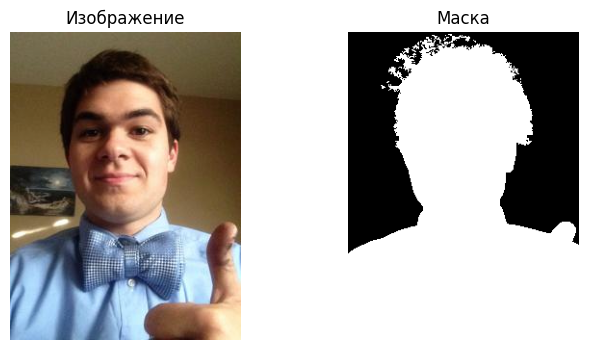

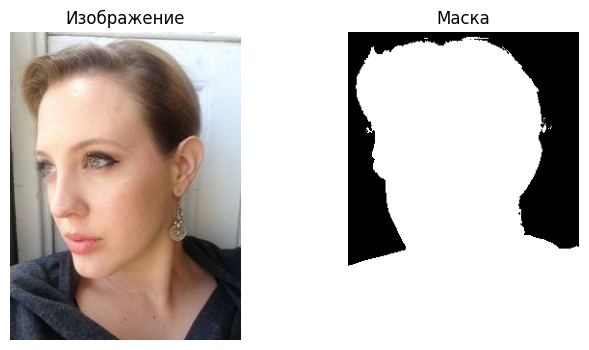

In [6]:
def show_pair(image, mask, prediction=None):
    image = image.detach().cpu().permute(1, 2, 0).numpy()
    image = image * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)
    mask = mask.detach().cpu().squeeze().numpy()
    ncols = 3 if prediction is not None else 2
    fig, axes = plt.subplots(1, ncols, figsize=(4 * ncols, 4))
    axes[0].imshow(image)
    axes[0].set_title('Изображение')
    axes[1].imshow(mask, cmap='gray', vmin=0, vmax=1)
    axes[1].set_title('Маска')
    if prediction is not None:
        axes[2].imshow(prediction.detach().cpu().squeeze().numpy(), cmap='gray', vmin=0, vmax=1)
        axes[2].set_title('Предсказание')
    for ax in axes:
        ax.set_axis_off()
    plt.show()

if DATA_READY:
    for idx in range(min(3, len(train_dataset))):
        show_pair(*train_dataset[idx])

<font color='MediumOrchid'>**Ваш вывод здесь:**</font>

Кратко опишите, как вы проверили синхронность аугментаций для изображения и маски.

с помощью функции show_pair были выведены исходные изображения и соответствующие им маски после применения случайных геометрических преобразований (таких как RandomHorizontalFlip и Resize). Если силуэт человека на фотографии отражается по горизонтали, то то же самое происходит и с его бинарным контуром на маске. Точки контура маски совпадают с границами человека на измененной картинке.

## <font color='DarkOrange'> **Задание 3 [2 балла]** </font>
---

Реализуйте `DiceLoss` и `IoUScore` для бинарной сегментации.

В `DiceLoss` при `with_logits=True` сначала применяйте сигмоиду. Поддержите значения `reduction`: `None`, `'mean'`, `'sum'`. В `IoUScore` порог применяется к логитам, а при пустом объединении значение метрики не должно быть `NaN`.

In [7]:
class DiceLoss(torch.nn.Module):
    def __init__(self, eps=1e-7, reduction='mean', with_logits=True):
        super().__init__()
        self.eps = eps
        self.reduction = reduction
        self.with_logits = with_logits

    def forward(self, logits, true_labels):
        #if self.with_logits:
        logits = torch.sigmoid(logits)

        intersection = torch.sum(logits * true_labels, dim=(1, 2, 3))
        union = torch.sum(logits, dim=(1, 2, 3)) + torch.sum(true_labels, dim=(1, 2, 3))
        dice = (2 * intersection + self.eps) / (union + self.eps)
        loss = 1 - dice

        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        return loss  # для reduction=None

class IoUScore(torch.nn.Module):
    def __init__(self, threshold=0.0, reduction='mean'):
        super().__init__()
        self.threshold = threshold
        self.reduction = reduction

    @torch.no_grad()
    def forward(self, logits, true_labels):
        pred_labels = (logits > self.threshold).float()
        dims = tuple(range(1, logits.dim())) # для 4D тензора (B, C, H, W) это будет (1, 2, 3)
        intersection = torch.sum(pred_labels * true_labels, dim=dims)
        union = torch.sum(pred_labels, dim=dims) + torch.sum(true_labels, dim=dims)
        iou = intersection / (union - intersection + 1e-7)
        if self.reduction == 'mean':
            return iou.mean()
        elif self.reduction == 'sum':
            return iou.sum()
        elif self.reduction is None or self.reduction == 'none':
            return iou
            
        raise ValueError(f"Unknown reduction: {self.reduction}")

In [8]:
_pred = torch.tensor([[[[1.0, 0.0], [0.0, 1.0]]]])
_target = torch.tensor([[[[1.0, 0.0], [1.0, 0.0]]]])
_loss = DiceLoss(with_logits=False, reduction='mean')(_pred, _target)
_score = IoUScore(threshold=0.5, reduction='mean')(_pred, _target)
assert torch.isfinite(_loss) and torch.isfinite(_score)
assert 0 <= _loss.item() <= 1
assert 0 <= _score.item() <= 1
print('Отлично!')

Отлично!


## <font color='DarkOrange'> **Задание 4 [2.5 балла]** </font>
---

Реализуйте декодер и соберите U-Net. Encoder уже реализован на основе первых блоков VGG13. Каждый `DecoderBlock` должен увеличить пространственное разрешение в два раза, объединить декодерный тензор с соответствующей активацией encoder по канальному измерению, затем применить две свёртки.

Для `UNet(num_blocks=3)` используйте encoder из трёх блоков, декодер из двух блоков и финальную свёртку `1x1`. Параметр `weights` передавайте в `VGG13Encoder`: он понадобится для бонуса.

In [9]:
class VGG13Encoder(torch.nn.Module):
    def __init__(self, num_blocks=3, weights=None):
        super().__init__()
        features = vgg13(weights=weights).features
        self.blocks = torch.nn.ModuleList()
        for idx in range(num_blocks):
            start = idx * 5
            self.blocks.append(torch.nn.Sequential(*[features[i] for i in range(start, start + 4)]))

    def forward(self, x):
        activations = []
        for block in self.blocks:
            x = block(x)
            activations.append(x)
            x = torch.nn.functional.max_pool2d(x, kernel_size=2, stride=2)
        return activations


class DecoderBlock(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = torch.nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.conv1 = torch.nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.conv2 = torch.nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)

    def forward(self, down, left):
        x = self.up(down)
        x = torch.cat([left, x], dim=1)  # concat по каналам
        x = torch.nn.functional.relu(self.conv1(x))
        x = torch.nn.functional.relu(self.conv2(x))
        return x


class Decoder(torch.nn.Module):
    def __init__(self, activations_channels):
        super().__init__()
        self.blocks = torch.nn.ModuleList()
        # идём от глубоких к мелким: left каналы = activations_channels[:-1] в обратном порядке
        for i in range(len(activations_channels) - 1):
            down_ch = activations_channels[-1 - i]   # каналы down (глубокого)
            left_ch = activations_channels[-2 - i]   # каналы left (мелкого)
            out_ch = left_ch                          # выходим в каналы мелкого уровня
            self.blocks.append(DecoderBlock(down_ch + left_ch, out_ch))

    def forward(self, activations):
        down = activations[-1]
        for i, block in enumerate(self.blocks):
            left = activations[-(i + 2)]
            down = block(down, left)
        return down


class UNet(torch.nn.Module):
    def __init__(self, num_classes=1, num_blocks=3, weights=None):
        super().__init__()
        self.encoder = VGG13Encoder(num_blocks=num_blocks, weights=weights)
        # получаем каналы активаций из первого прогона или по конфигурации VGG
        self.decoder = Decoder(activations_channels=[64, 128, 256][:num_blocks])
        # последний блок декодера выдаёт каналы самого мелкого уровня (64)
        self.final_conv = torch.nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        activations = self.encoder(x)
        x = self.decoder(activations)
        x = self.final_conv(x)
        return x        

In [10]:
_model_check = UNet(num_classes=1, num_blocks=3)
_x = torch.randn(2, 3, 320, 240)
_y = _model_check(_x)
assert _y.shape == (2, 1, 320, 240)
assert sum(p.numel() for p in _model_check.parameters()) > 1_000_000
print('Отлично!')

Отлично!


## <font color='DarkOrange'> **Задание 5 [2.5 балла]** </font>
---

Обучите U-Net. Используйте `DiceLoss` или комбинацию `BCEWithLogitsLoss` и `DiceLoss`; оптимизатор и параметры обучения выберите самостоятельно.

В ходе эксперимента:

- посчитайте loss и IoU на обучающей и тестовой выборках для каждой эпохи;
- постройте графики loss и IoU;
- покажите не менее трёх изображений с истинной и предсказанной масками;
- сохраните веса модели с лучшим значением test IoU.

Рекомендуется начать с 5-10 эпох и размера batch 8. Если не хватает памяти GPU, уменьшите размер batch.

Epoch 1/1 | train loss 0.2742 iou 0.5873 | test loss 0.2601 iou 0.6040


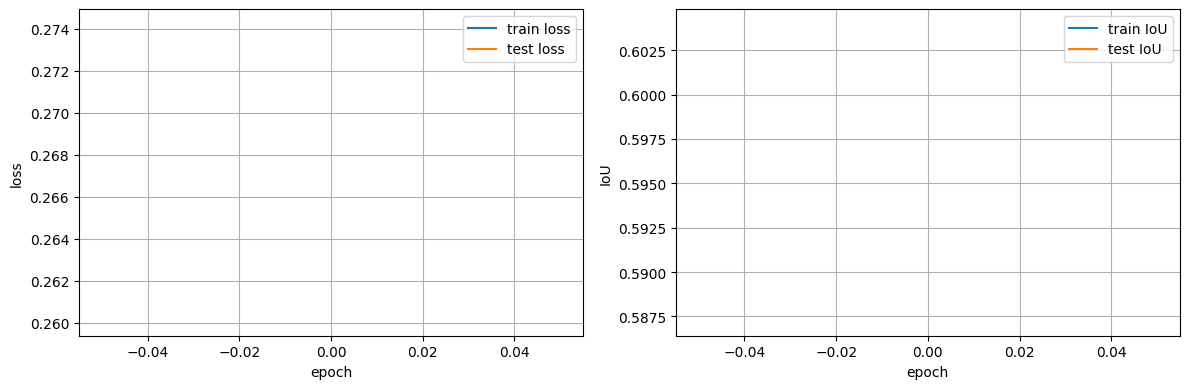

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.169412].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


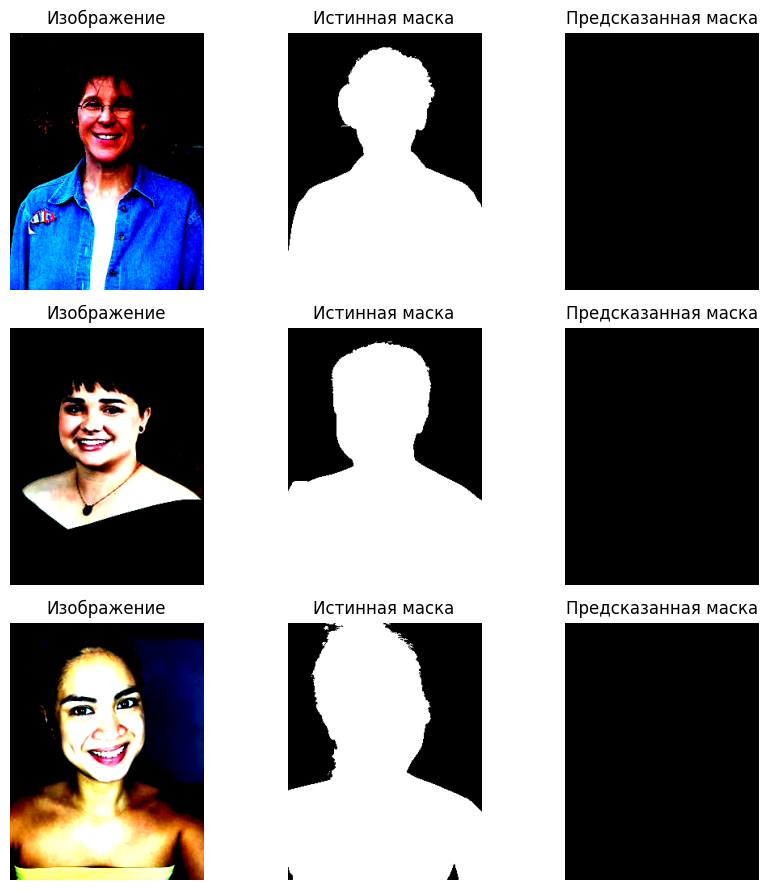

In [12]:
import torch
import torch.nn as nn
from torch.optim import Adam
import matplotlib.pyplot as plt

model = UNet(num_classes=1, num_blocks=3)

device_mac = 'mps'
device_cpu = 'cpu'

def run_epoch(loader, train=True):
        total_loss, total_iou, n = 0.0, 0.0, 0
        model.train() if train else model.eval()
        with torch.set_grad_enabled(train):
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                if train:
                    optimizer.zero_grad()
                pred = model(x)
                loss = criterion(pred, y)
                if train:
                    loss.backward()
                    optimizer.step()
                total_loss += loss.item() * x.size(0)
                total_iou += iou_metric(pred, y).item() * x.size(0)
                n += x.size(0)
        return total_loss / n, total_iou / n


if DATA_READY:
    device = torch.device('cuda' if torch.cuda.is_available() else device_mac)
    print(device)
    model = model.to(device)

    dice_loss = DiceLoss()            # sigmoid внутри — подаём логиты
    bce_loss = nn.BCEWithLogitsLoss() # тоже логиты
    iou_metric = IoUScore(threshold=0.0)

    criterion = dice_loss
    optimizer = Adam(model.parameters(), lr=1e-3)

    epochs = 1

    train_hist, test_hist = [], []
    best_test_iou = 0.0
    for epoch in range(epochs):
        tr_loss, tr_iou = run_epoch(train_data_loader, train=True)
        te_loss, te_iou = run_epoch(test_data_loader, train=False)
        train_hist.append((tr_loss, tr_iou))
        test_hist.append((te_loss, te_iou))
        print(f'Epoch {epoch+1}/{epochs} | train loss {tr_loss:.4f} iou {tr_iou:.4f} | '
              f'test loss {te_loss:.4f} iou {te_iou:.4f}')

        if te_iou > best_test_iou:
            best_test_iou = te_iou
            torch.save(model.state_dict(), 'best_unet.pth')

    # --- Графики loss и IoU ---
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot([h[0] for h in train_hist], label='train loss')
    plt.plot([h[0] for h in test_hist], label='test loss')
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot([h[1] for h in train_hist], label='train IoU')
    plt.plot([h[1] for h in test_hist], label='test IoU')
    plt.xlabel('epoch'); plt.ylabel('IoU'); plt.legend(); plt.grid()
    plt.tight_layout(); plt.show()

    # --- Показ 3 изображений с истинными и предсказанными масками ---
    model.eval()
    with torch.no_grad():
        imgs, masks = next(iter(test_data_loader))
        preds = (torch.sigmoid(model(imgs.to(device))) > 0.5).float().cpu()

    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for i in range(3):
        axes[i, 0].imshow(imgs[i].permute(1, 2, 0))
        axes[i, 0].set_title('Изображение')
        axes[i, 1].imshow(masks[i].squeeze(), cmap='gray')
        axes[i, 1].set_title('Истинная маска')
        axes[i, 2].imshow(preds[i].squeeze(), cmap='gray')
        axes[i, 2].set_title('Предсказанная маска')
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout(); plt.show()
    
else:
    print('Сначала подготовьте датасет и перезапустите ячейки с его загрузкой.')

<font color='MediumOrchid'>**Ваш вывод здесь:**</font>

Сопоставьте кривые обучения с визуальным качеством масок. Укажите, какие ошибки встречаются у модели чаще всего.

## <font color='MediumSeaGreen'>Бонус [до 1 балла]</font>

Создайте модель с `weights=VGG13_Weights.DEFAULT` и сравните её с вариантом без предобучения при одинаковом числе эпох.